# Studi Komparatif Empiris Model Generatif & Pembuktian Batasan Teoretis MLP Classifier
**Mata Kuliah**: Deep Learning (D6421) — Sesi 07: Generative Models terintegrasi Sesi 06 (Autoencoders)  
**Benchmark Dataset**: Fashion-MNIST ($28 \times 28$ Grayscale, 70.000 Citra: 80% Train / 10% Val / 10% Test)  
**Parameter Standar**: `SEED = 42`, `BATCH_SIZE = 256`, Ruang Laten Autoencoder Seragam $\mathbb{R}^{64}$, DDPM $T = 400$


## Bagian 1: Inisialisasi Lingkungan, Penetapan Random Seed, dan Data Pipeline


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import math
import random
import time
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.models import Inception_V3_Weights, inception_v3

SEED = 42
BATCH_SIZE = 256
LATENT_DIM_AE = 64
LATENT_DIM_GAN = 64
LATENT_DIM_DCGAN = 100
DDPM_STEPS = 400
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABEL_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

def fix_random_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fix_random_seeds(SEED)
print(f"Active Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Active Device: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


In [2]:
ds_train_raw = datasets.FashionMNIST("data", train=True, download=True)
ds_test_raw = datasets.FashionMNIST("data", train=False, download=True)

x_all = torch.cat([ds_train_raw.data, ds_test_raw.data], dim=0).unsqueeze(1).float() / 255.0
y_all = torch.cat([ds_train_raw.targets, ds_test_raw.targets], dim=0)
dataset_full = TensorDataset(x_all, y_all)

train_set, val_set, test_set = random_split(
    dataset_full,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

print(f"Partisi Dataset -> Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)} | Batch Size: {BATCH_SIZE}")

Partisi Dataset -> Train: 56000 | Val: 7000 | Test: 7000 | Batch Size: 256


## Bagian 2: Eksperimen Pembuktian 5 Tahap Batasan MLP Classifier untuk Image Generation
Membuktikan secara empiris mengapa jaringan diskriminatif $784 \to 256 \to 64 \to 10$ yang memodelkan $P(y \mid x)$ tidak mampu merekonstruksi maupun menyintesis citra baru.


In [3]:
class DiscriminativeMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784, 256)
        self.layer2 = nn.Linear(256, 64)
        self.head = nn.Linear(64, 10)

    def encode_features(self, x):
        flat = x.view(x.size(0), -1)
        h1 = F.relu(self.layer1(flat))
        return F.relu(self.layer2(h1))

    def forward(self, x):
        return self.head(self.encode_features(x))

    @torch.no_grad()
    def project_from_onehot(self, y_onehot):
        z_hat = F.relu(y_onehot @ self.head.weight)
        h1_hat = F.relu(z_hat @ self.layer2.weight)
        return torch.sigmoid(h1_hat @ self.layer1.weight).view(-1, 1, 28, 28)

    @torch.no_grad()
    def project_from_latent(self, z_mlp):
        h1_hat = F.relu(z_mlp @ self.layer2.weight)
        return torch.sigmoid(h1_hat @ self.layer1.weight).view(-1, 1, 28, 28)


class SeparateMLPDecoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )

    def forward(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

In [4]:
fix_random_seeds()
mlp_clf = DiscriminativeMLP().to(DEVICE)
opt_mlp = torch.optim.AdamW(mlp_clf.parameters(), lr=1.5e-3, weight_decay=1e-4)

for ep in range(22):
    mlp_clf.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt_mlp.zero_grad()
        F.cross_entropy(mlp_clf(xb), yb).backward()
        opt_mlp.step()

mlp_clf.eval()
correct = sum((mlp_clf(xb.to(DEVICE)).argmax(1) == yb.to(DEVICE)).sum().item() for xb, yb in test_loader)
mlp_test_acc = correct / len(test_set) * 100.0
print(f"[Tahap 1] MLP Classifier Test Accuracy: {mlp_test_acc:.2f}% (Target >= 88.0%)")

for w_name, layer in [("W1", mlp_clf.layer1), ("W2", mlp_clf.layer2), ("W3", mlp_clf.head)]:
    W = layer.weight.detach()
    err_wtw = torch.norm(W.T @ W - torch.eye(W.shape[1], device=DEVICE), p="fro").item()
    err_wwt = torch.norm(W @ W.T - torch.eye(W.shape[0], device=DEVICE), p="fro").item()
    print(f"  Matriks {w_name} {tuple(W.shape)} -> ||W^T W - I||_F = {err_wtw:.3f} | ||W W^T - I||_F = {err_wwt:.3f}")

# Tahap 4: Bekukan bobot MLP Classifier & latih SeparateMLPDecoder (64 -> 256 -> 784)
for p in mlp_clf.parameters():
    p.requires_grad = False

fix_random_seeds()
frozen_decoder = SeparateMLPDecoder(LATENT_DIM_AE).to(DEVICE)
opt_fdec = torch.optim.Adam(frozen_decoder.parameters(), lr=1.2e-3)
for ep in range(25):
    frozen_decoder.train()
    for xb, _ in train_loader:
        xb = xb.to(DEVICE)
        with torch.no_grad():
            z_f = mlp_clf.encode_features(xb)
        opt_fdec.zero_grad()
        F.mse_loss(frozen_decoder(z_f), xb).backward()
        opt_fdec.step()
frozen_decoder.eval()
print("[Tahap 4] Frozen Latent Decoder selesai dilatih (25 epoch).")

[Tahap 1] MLP Classifier Test Accuracy: 88.84% (Target >= 88.0%)
  Matriks W1 (256, 784) -> ||W^T W - I||_F = 487.348 | ||W W^T - I||_F = 486.806
  Matriks W2 (64, 256) -> ||W^T W - I||_F = 65.842 | ||W W^T - I||_F = 64.367
  Matriks W3 (10, 64) -> ||W^T W - I||_F = 11.697 | ||W W^T - I||_F = 9.101
[Tahap 4] Frozen Latent Decoder selesai dilatih (25 epoch).


## Bagian 3: Implementasi & Pelatihan Keluarga Autoencoder (Vanilla AE, Sparse AE, dan VAE)
Ketiga arsitektur dirancang memiliki dimensi bottleneck laten seragam ($d_z = 64$) untuk mengisolasi dampak murni dari regularisasi kejarangan $L_1$ ($\lambda \|h\|_1$) dan regularisasi kerapatan prior Gaussian $D_{\text{KL}}(q_\phi(z|x) \parallel \mathcal{N}(0,I))$.


In [5]:
class DeterministicAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.enc_net = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latent_dim))
        self.dec_net = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x): return self.enc_net(x.view(x.size(0), -1))
    def decode(self, z): return self.dec_net(z).view(-1, 1, 28, 28)
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class L1SparseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.enc_net = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latent_dim), nn.ReLU())
        self.dec_net = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x): return self.enc_net(x.view(x.size(0), -1))
    def decode(self, h): return self.dec_net(h).view(-1, 1, 28, 28)
    def forward(self, x):
        h = self.encode(x)
        return self.decode(h), h


class GaussianVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.backbone = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        self.mu_head = nn.Linear(256, latent_dim)
        self.logvar_head = nn.Linear(256, latent_dim)
        self.dec_net = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.backbone(x.view(x.size(0), -1))
        return self.mu_head(h), self.logvar_head(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(logvar)

    def decode(self, z): return self.dec_net(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

    @torch.no_grad()
    def synthesize(self, num_samples):
        return self.decode(torch.randn(num_samples, self.latent_dim, device=DEVICE))

In [6]:
logs = {
    "vanilla_ae_loss": [], "sparse_ae_mse": [], "sparse_ae_sparsity": [],
    "vae_elbo": [], "vae_bce": [], "vae_kld": [],
    "gan_g": [], "gan_d": [], "dcgan_g": [], "dcgan_d": [],
    "ddpm_train": [], "ddpm_val": []
}
train_time_per_epoch = {}

# 1. Vanilla AE (25 Epoch)
fix_random_seeds()
model_vae_det = DeterministicAE(LATENT_DIM_AE).to(DEVICE)
opt_ae = torch.optim.Adam(model_vae_det.parameters(), lr=1.2e-3)
t0 = time.perf_counter()
for _ in range(25):
    model_vae_det.train()
    ep_loss = 0.0
    for xb, _ in train_loader:
        xb = xb.to(DEVICE)
        opt_ae.zero_grad()
        loss = F.mse_loss(model_vae_det(xb)[0], xb)
        loss.backward()
        opt_ae.step()
        ep_loss += loss.item() * xb.size(0)
    logs["vanilla_ae_loss"].append(ep_loss / len(train_set))
train_time_per_epoch["Vanilla AE"] = (time.perf_counter() - t0) / 25
print(f"[Vanilla AE] Final Train MSE: {logs['vanilla_ae_loss'][-1]:.5f} | {train_time_per_epoch['Vanilla AE']:.2f}s/epoch")

# 2. Sparse AE (25 Epoch, lambda = 1.2e-3)
fix_random_seeds()
model_sparse_ae = L1SparseAE(LATENT_DIM_AE).to(DEVICE)
opt_sae = torch.optim.Adam(model_sparse_ae.parameters(), lr=1.2e-3)
t0 = time.perf_counter()
for _ in range(25):
    model_sparse_ae.train()
    ep_mse = 0.0
    for xb, _ in train_loader:
        xb = xb.to(DEVICE)
        opt_sae.zero_grad()
        xh, h_lat = model_sparse_ae(xb)
        mse_val = F.mse_loss(xh, xb)
        (mse_val + 1.2e-3 * h_lat.abs().mean()).backward()
        opt_sae.step()
        ep_mse += mse_val.item() * xb.size(0)
    logs["sparse_ae_mse"].append(ep_mse / len(train_set))
    model_sparse_ae.eval()
    with torch.no_grad():
        sp = np.mean([(model_sparse_ae.encode(vx.to(DEVICE)).abs() < 1e-2).float().mean().item() for vx, _ in val_loader])
        logs["sparse_ae_sparsity"].append(float(sp * 100.0))
train_time_per_epoch["Sparse AE"] = (time.perf_counter() - t0) / 25
print(f"[Sparse AE]  Final Train MSE: {logs['sparse_ae_mse'][-1]:.5f} | Active Sparsity: {logs['sparse_ae_sparsity'][-1]:.1f}% | {train_time_per_epoch['Sparse AE']:.2f}s/epoch")

# 3. Variational Autoencoder (28 Epoch, Negative ELBO)
fix_random_seeds()
model_vae = GaussianVAE(LATENT_DIM_AE).to(DEVICE)
opt_vae = torch.optim.Adam(model_vae.parameters(), lr=1.2e-3)
t0 = time.perf_counter()
for _ in range(28):
    model_vae.train()
    s_elbo = s_bce = s_kl = 0.0
    for xb, _ in train_loader:
        xb = xb.to(DEVICE)
        opt_vae.zero_grad()
        xh, mu, logvar = model_vae(xb)
        bce = F.binary_cross_entropy(xh, xb, reduction="sum") / xb.size(0)
        kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / xb.size(0)
        loss = bce + kl
        loss.backward()
        opt_vae.step()
        bs = xb.size(0)
        s_elbo += loss.item() * bs; s_bce += bce.item() * bs; s_kl += kl.item() * bs
    logs["vae_elbo"].append(s_elbo / len(train_set))
    logs["vae_bce"].append(s_bce / len(train_set))
    logs["vae_kld"].append(s_kl / len(train_set))
train_time_per_epoch["VAE"] = (time.perf_counter() - t0) / 28
print(f"[VAE]        Final ELBO: {logs['vae_elbo'][-1]:.2f} (BCE: {logs['vae_bce'][-1]:.2f}, KL: {logs['vae_kld'][-1]:.2f}) | {train_time_per_epoch['VAE']:.2f}s/epoch")

[Vanilla AE] Final Train MSE: 0.00726 | 1.52s/epoch
[Sparse AE]  Final Train MSE: 0.00884 | Active Sparsity: 39.4% | 1.57s/epoch
[VAE]        Final ELBO: 237.63 (BCE: 224.82, KL: 12.81) | 1.81s/epoch


## Bagian 4: Implementasi & Pelatihan Keluarga Adversarial (Vanilla GAN vs DCGAN)


In [7]:
class MLPGenerator(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.z_dim = z_dim
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 784), nn.Tanh()
        )

    def forward(self, z): return self.model(z).view(-1, 1, 28, 28)
    @torch.no_grad()
    def synthesize(self, n): return (self.forward(torch.randn(n, self.z_dim, device=DEVICE)) + 1.0) * 0.5


class MLPDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(784, 512), nn.LeakyReLU(0.2, inplace=True), nn.Dropout(0.25),
            nn.Linear(512, 256), nn.LeakyReLU(0.2, inplace=True), nn.Dropout(0.25),
            nn.Linear(256, 1)
        )

    def forward(self, x): return self.model(x.view(x.size(0), -1)).squeeze(1)


def init_conv_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.constant_(m.bias, 0.0)


class ConvGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.Conv2d(64, 1, 3, 1, 1, bias=False), nn.Tanh()
        )
        self.apply(init_conv_weights)

    def forward(self, z): return self.net(z.view(z.size(0), self.z_dim, 1, 1))
    @torch.no_grad()
    def synthesize(self, n): return (self.forward(torch.randn(n, self.z_dim, device=DEVICE)) + 1.0) * 0.5


class ConvDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, 7, 1, 0, bias=False)
        )
        self.apply(init_conv_weights)

    def forward(self, x): return self.net(x).view(-1)

In [8]:
def run_adversarial_training(G, D, z_dim, num_epochs, g_log_key, d_log_key, label):
    opt_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    criterion = nn.BCEWithLogitsLoss()
    t0 = time.perf_counter()
    for _ in range(num_epochs):
        G.train(); D.train()
        g_tot = d_tot = steps = 0
        for xb, _ in train_loader:
            real_x = xb.to(DEVICE) * 2.0 - 1.0
            bs = real_x.size(0)
            valid = torch.ones(bs, device=DEVICE)
            fake_lbl = torch.zeros(bs, device=DEVICE)

            opt_d.zero_grad()
            gen_x = G(torch.randn(bs, z_dim, device=DEVICE)).detach()
            d_loss = criterion(D(real_x), valid) + criterion(D(gen_x), fake_lbl)
            d_loss.backward(); opt_d.step()

            opt_g.zero_grad()
            g_loss = criterion(D(G(torch.randn(bs, z_dim, device=DEVICE))), valid)
            g_loss.backward(); opt_g.step()

            g_tot += g_loss.item(); d_tot += d_loss.item(); steps += 1
        logs[g_log_key].append(g_tot / steps)
        logs[d_log_key].append(d_tot / steps)
    train_time_per_epoch[label] = (time.perf_counter() - t0) / num_epochs
    print(f"[{label}] G Loss: {logs[g_log_key][-1]:.3f} | D Loss: {logs[d_log_key][-1]:.3f} | {train_time_per_epoch[label]:.2f}s/epoch")

fix_random_seeds()
vgan_g, vgan_d = MLPGenerator(LATENT_DIM_GAN).to(DEVICE), MLPDiscriminator().to(DEVICE)
run_adversarial_training(vgan_g, vgan_d, LATENT_DIM_GAN, 35, "gan_g", "gan_d", "Vanilla GAN")

fix_random_seeds()
dcgan_g, dcgan_d = ConvGenerator(LATENT_DIM_DCGAN).to(DEVICE), ConvDiscriminator().to(DEVICE)
run_adversarial_training(dcgan_g, dcgan_d, LATENT_DIM_DCGAN, 35, "dcgan_g", "dcgan_d", "DCGAN")

[Vanilla GAN] G Loss: 1.322 | D Loss: 1.040 | 2.37s/epoch
[DCGAN] G Loss: 0.831 | D Loss: 1.346 | 12.92s/epoch


## Bagian 5: Implementasi & Pelatihan Denoising Diffusion Probabilistic Model (DDPM U-Net, $T = 400$)


In [9]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        emb = torch.exp(torch.arange(half, device=t.device) * -(math.log(10000) / (half - 1)))
        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([emb.sin(), emb.cos()], dim=-1)


class ResidualTimeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.time_mlp = nn.Linear(time_dim, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = F.silu(self.norm1(self.conv1(x))) + self.time_mlp(F.silu(t_emb)).unsqueeze(-1).unsqueeze(-1)
        return F.silu(self.norm2(self.conv2(h))) + self.shortcut(x)


class DenoisingUNet(nn.Module):
    def __init__(self, base_ch=64, time_dim=128):
        super().__init__()
        self.time_proj = nn.Sequential(
            SinusoidalPosEmb(time_dim), nn.Linear(time_dim, time_dim), nn.SiLU(), nn.Linear(time_dim, time_dim)
        )
        self.enc1 = ResidualTimeBlock(1, base_ch, time_dim); self.down1 = nn.Conv2d(base_ch, base_ch, 4, 2, 1)
        self.enc2 = ResidualTimeBlock(base_ch, base_ch * 2, time_dim); self.down2 = nn.Conv2d(base_ch * 2, base_ch * 2, 4, 2, 1)
        self.mid1 = ResidualTimeBlock(base_ch * 2, base_ch * 2, time_dim); self.mid2 = ResidualTimeBlock(base_ch * 2, base_ch * 2, time_dim)
        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch * 2, 4, 2, 1); self.dec1 = ResidualTimeBlock(base_ch * 4, base_ch, time_dim)
        self.up2 = nn.ConvTranspose2d(base_ch, base_ch, 4, 2, 1); self.dec2 = ResidualTimeBlock(base_ch * 2, base_ch, time_dim)
        self.final_conv = nn.Conv2d(base_ch, 1, 1)

    def forward(self, x, t):
        t_emb = self.time_proj(t)
        e1 = self.enc1(x, t_emb)
        e2 = self.enc2(self.down1(e1), t_emb)
        m = self.mid2(self.mid1(self.down2(e2), t_emb), t_emb)
        d1 = self.dec1(torch.cat([self.up1(m), e2], dim=1), t_emb)
        d2 = self.dec2(torch.cat([self.up2(d1), e1], dim=1), t_emb)
        return self.final_conv(d2)


class GaussianDDPM(nn.Module):
    def __init__(self, timesteps=DDPM_STEPS):
        super().__init__()
        self.unet = DenoisingUNet(base_ch=64, time_dim=128)
        self.T = timesteps
        betas = torch.linspace(1e-4, 0.02, timesteps)
        alphas = 1.0 - betas
        alpha_bar = torch.cumprod(alphas, dim=0)
        alpha_bar_prev = F.pad(alpha_bar[:-1], (1, 0), value=1.0)
        self.register_buffer("betas", betas)
        self.register_buffer("sqrt_alpha_bar", torch.sqrt(alpha_bar))
        self.register_buffer("sqrt_one_minus_alpha_bar", torch.sqrt(1.0 - alpha_bar))
        self.register_buffer("sqrt_recip_alphas", torch.sqrt(1.0 / alphas))
        self.register_buffer("posterior_var", betas * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar))

    def compute_loss(self, x0_unit):
        x0 = x0_unit * 2.0 - 1.0
        t = torch.randint(0, self.T, (x0.size(0),), device=x0.device, dtype=torch.long)
        noise = torch.randn_like(x0)
        xt = self.sqrt_alpha_bar[t][:, None, None, None] * x0 + self.sqrt_one_minus_alpha_bar[t][:, None, None, None] * noise
        return F.mse_loss(self.unet(xt, t), noise)

    @torch.no_grad()
    def synthesize(self, num_samples, record_steps=None):
        x = torch.randn(num_samples, 1, 28, 28, device=DEVICE)
        snapshots = []
        if record_steps and self.T in record_steps:
            snapshots.append((self.T, ((x.clamp(-1, 1) + 1.0) * 0.5).cpu()))
        for step in reversed(range(self.T)):
            t_batch = torch.full((num_samples,), step, device=DEVICE, dtype=torch.long)
            eps_hat = self.unet(x, t_batch)
            mean = self.sqrt_recip_alphas[step] * (x - (self.betas[step] / self.sqrt_one_minus_alpha_bar[step]) * eps_hat)
            x = mean + torch.sqrt(self.posterior_var[step]) * torch.randn_like(x) if step > 0 else mean
            if record_steps and step in record_steps:
                snapshots.append((step, ((x.clamp(-1, 1) + 1.0) * 0.5).cpu()))
        final_img = (x.clamp(-1, 1) + 1.0) * 0.5
        return (final_img, snapshots) if record_steps else final_img

In [10]:
fix_random_seeds()
model_ddpm = GaussianDDPM(DDPM_STEPS).to(DEVICE)
opt_ddpm = torch.optim.AdamW(model_ddpm.parameters(), lr=2.5e-4, weight_decay=1e-4)
t0 = time.perf_counter()

for ep in range(30):
    model_ddpm.train()
    tr_sum = 0.0
    for xb, _ in train_loader:
        xb = xb.to(DEVICE)
        opt_ddpm.zero_grad()
        loss = model_ddpm.compute_loss(xb)
        loss.backward()
        nn.utils.clip_grad_norm_(model_ddpm.parameters(), 1.0)
        opt_ddpm.step()
        tr_sum += loss.item() * xb.size(0)
    logs["ddpm_train"].append(tr_sum / len(train_set))

    model_ddpm.eval()
    with torch.no_grad():
        val_sum = sum(model_ddpm.compute_loss(vx.to(DEVICE)).item() * vx.size(0) for vx, _ in val_loader)
    logs["ddpm_val"].append(val_sum / len(val_set))

train_time_per_epoch["DDPM"] = (time.perf_counter() - t0) / 30
print(f"[DDPM] Final Val Noise MSE: {logs['ddpm_val'][-1]:.5f} | {train_time_per_epoch['DDPM']:.2f}s/epoch")

[DDPM] Final Val Noise MSE: 0.05933 | 30.16s/epoch


## Bagian 6: Evaluasi Metrik Kuantitatif Test Set (MSE, PSNR, SSIM, Latensi Inferensi, dan FID)


In [11]:
def compute_ssim_batch(img1, img2):
    grid = torch.arange(7, dtype=torch.float32, device=img1.device) - 3
    gauss = torch.exp(-(grid ** 2) / 4.5)
    gauss = gauss / gauss.sum()
    kernel = (gauss[:, None] @ gauss[None, :]).view(1, 1, 7, 7)
    mu1, mu2 = F.conv2d(img1, kernel, padding=3), F.conv2d(img2, kernel, padding=3)
    sig1 = F.conv2d(img1 * img1, kernel, padding=3) - mu1 ** 2
    sig2 = F.conv2d(img2 * img2, kernel, padding=3) - mu2 ** 2
    sig12 = F.conv2d(img1 * img2, kernel, padding=3) - mu1 * mu2
    ssim_map = ((2 * mu1 * mu2 + 1e-4) * (2 * sig12 + 9e-4)) / ((mu1 ** 2 + mu2 ** 2 + 1e-4) * (sig1 + sig2 + 9e-4))
    return ssim_map.mean(dim=(1, 2, 3))

@torch.no_grad()
def evaluate_reconstruction(recon_fn):
    mse_list, psnr_list, ssim_list = [], [], []
    for xb, _ in test_loader:
        xb = xb.to(DEVICE)
        x_rec = recon_fn(xb).clamp(0.0, 1.0)
        mse_b = ((xb - x_rec) ** 2).mean(dim=(1, 2, 3))
        mse_list.append(mse_b.cpu())
        psnr_list.append((10.0 * torch.log10(1.0 / (mse_b + 1e-10))).cpu())
        ssim_list.append(compute_ssim_batch(xb, x_rec).cpu())
    return {
        "test_mse": round(float(torch.cat(mse_list).mean()), 6),
        "test_psnr": round(float(torch.cat(psnr_list).mean()), 2),
        "test_ssim": round(float(torch.cat(ssim_list).mean()), 4)
    }

def benchmark_latency_ms(call_fn, repeats=25):
    with torch.no_grad():
        call_fn()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        timings = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            call_fn()
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            timings.append((time.perf_counter() - t0) * 1000.0)
    return round(float(np.mean(timings)), 3)

recon_metrics = {
    "Vanilla AE": evaluate_reconstruction(lambda x: model_vae_det(x)[0]),
    "Sparse AE": evaluate_reconstruction(lambda x: model_sparse_ae(x)[0]),
    "VAE": evaluate_reconstruction(lambda x: model_vae.decode(model_vae.encode(x)[0])),
    "Frozen MLP Decoder": evaluate_reconstruction(lambda x: frozen_decoder(mlp_clf.encode_features(x)))
}
for k, v in recon_metrics.items():
    print(f"{k:20s} -> Test MSE: {v['test_mse']:.5f} | PSNR: {v['test_psnr']:.2f} dB | SSIM: {v['test_ssim']:.4f}")

sample_batch_64 = next(iter(test_loader))[0][:64].to(DEVICE)
latency_batch64 = {
    "Vanilla AE": benchmark_latency_ms(lambda: model_vae_det(sample_batch_64)[0]),
    "Sparse AE": benchmark_latency_ms(lambda: model_sparse_ae(sample_batch_64)[0]),
    "VAE": benchmark_latency_ms(lambda: model_vae.synthesize(64)),
    "Vanilla GAN": benchmark_latency_ms(lambda: vgan_g.synthesize(64)),
    "DCGAN": benchmark_latency_ms(lambda: dcgan_g.synthesize(64)),
    "DDPM": round(benchmark_latency_ms(lambda: model_ddpm.synthesize(64), repeats=3), 2)
}
print("Inference Latency (ms / batch 64):", latency_batch64)

Vanilla AE           -> Test MSE: 0.00744 | PSNR: 22.33 dB | SSIM: 0.8383
Sparse AE            -> Test MSE: 0.00907 | PSNR: 21.42 dB | SSIM: 0.8048
VAE                  -> Test MSE: 0.01424 | PSNR: 19.36 dB | SSIM: 0.7557
Frozen MLP Decoder   -> Test MSE: 0.01730 | PSNR: 18.37 dB | SSIM: 0.7060
Inference Latency (ms / batch 64): {'Vanilla AE': 0.475, 'Sparse AE': 0.478, 'VAE': 0.495, 'Vanilla GAN': 0.493, 'DCGAN': 3.057, 'DDPM': 3262.14}


In [12]:
inception = inception_v3(weights=Inception_V3_Weights.DEFAULT, aux_logits=True)
inception.fc = nn.Identity()
inception.eval().to(DEVICE)

im_mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
im_std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

@torch.no_grad()
def extract_inception_features(images_tensor):
    feats = []
    for idx in range(0, len(images_tensor), 128):
        batch = images_tensor[idx:idx + 128].to(DEVICE).repeat(1, 3, 1, 1)
        resized = F.interpolate(batch, size=(299, 299), mode="bilinear", align_corners=False)
        feats.append(inception((resized - im_mean) / im_std).cpu().numpy())
    return np.concatenate(feats, axis=0)

def frechet_distance(f_real, f_fake):
    mu1, mu2 = f_real.mean(axis=0), f_fake.mean(axis=0)
    sigma1, sigma2 = np.cov(f_real, rowvar=False), np.cov(f_fake, rowvar=False)
    covmean = linalg.sqrtm(sigma1 @ sigma2).real
    diff = mu1 - mu2
    return float(diff @ diff + np.trace(sigma1 + sigma2 - 2.0 * covmean))

test_images_all = torch.cat([xb for xb, _ in test_loader], dim=0)
test_labels_all = torch.cat([yb for _, yb in test_loader], dim=0)
real_feats = extract_inception_features(test_images_all[:2000])

fid_results = {}
for m_name, gen_fn in [("VAE", model_vae.synthesize), ("Vanilla GAN", vgan_g.synthesize), ("DCGAN", dcgan_g.synthesize), ("DDPM", model_ddpm.synthesize)]:
    fix_random_seeds(SEED + 7)
    synth_imgs = torch.cat([gen_fn(200).cpu() for _ in range(10)], dim=0)
    fid_results[m_name] = round(frechet_distance(real_feats, extract_inception_features(synth_imgs)), 2)
    print(f"FID {m_name:12s}: {fid_results[m_name]:.2f}")

FID VAE         : 81.16
FID Vanilla GAN : 170.17
FID DCGAN       : 36.54
FID DDPM        : 37.35


## Bagian 7: Pembuatan Lima Visualisasi Komparatif Wajib (300 DPI)


Menampilkan Figur 1: Grid Rekonstruksi Side-by-Side (outputs/fig1_rekonstruksi_komparatif.png)


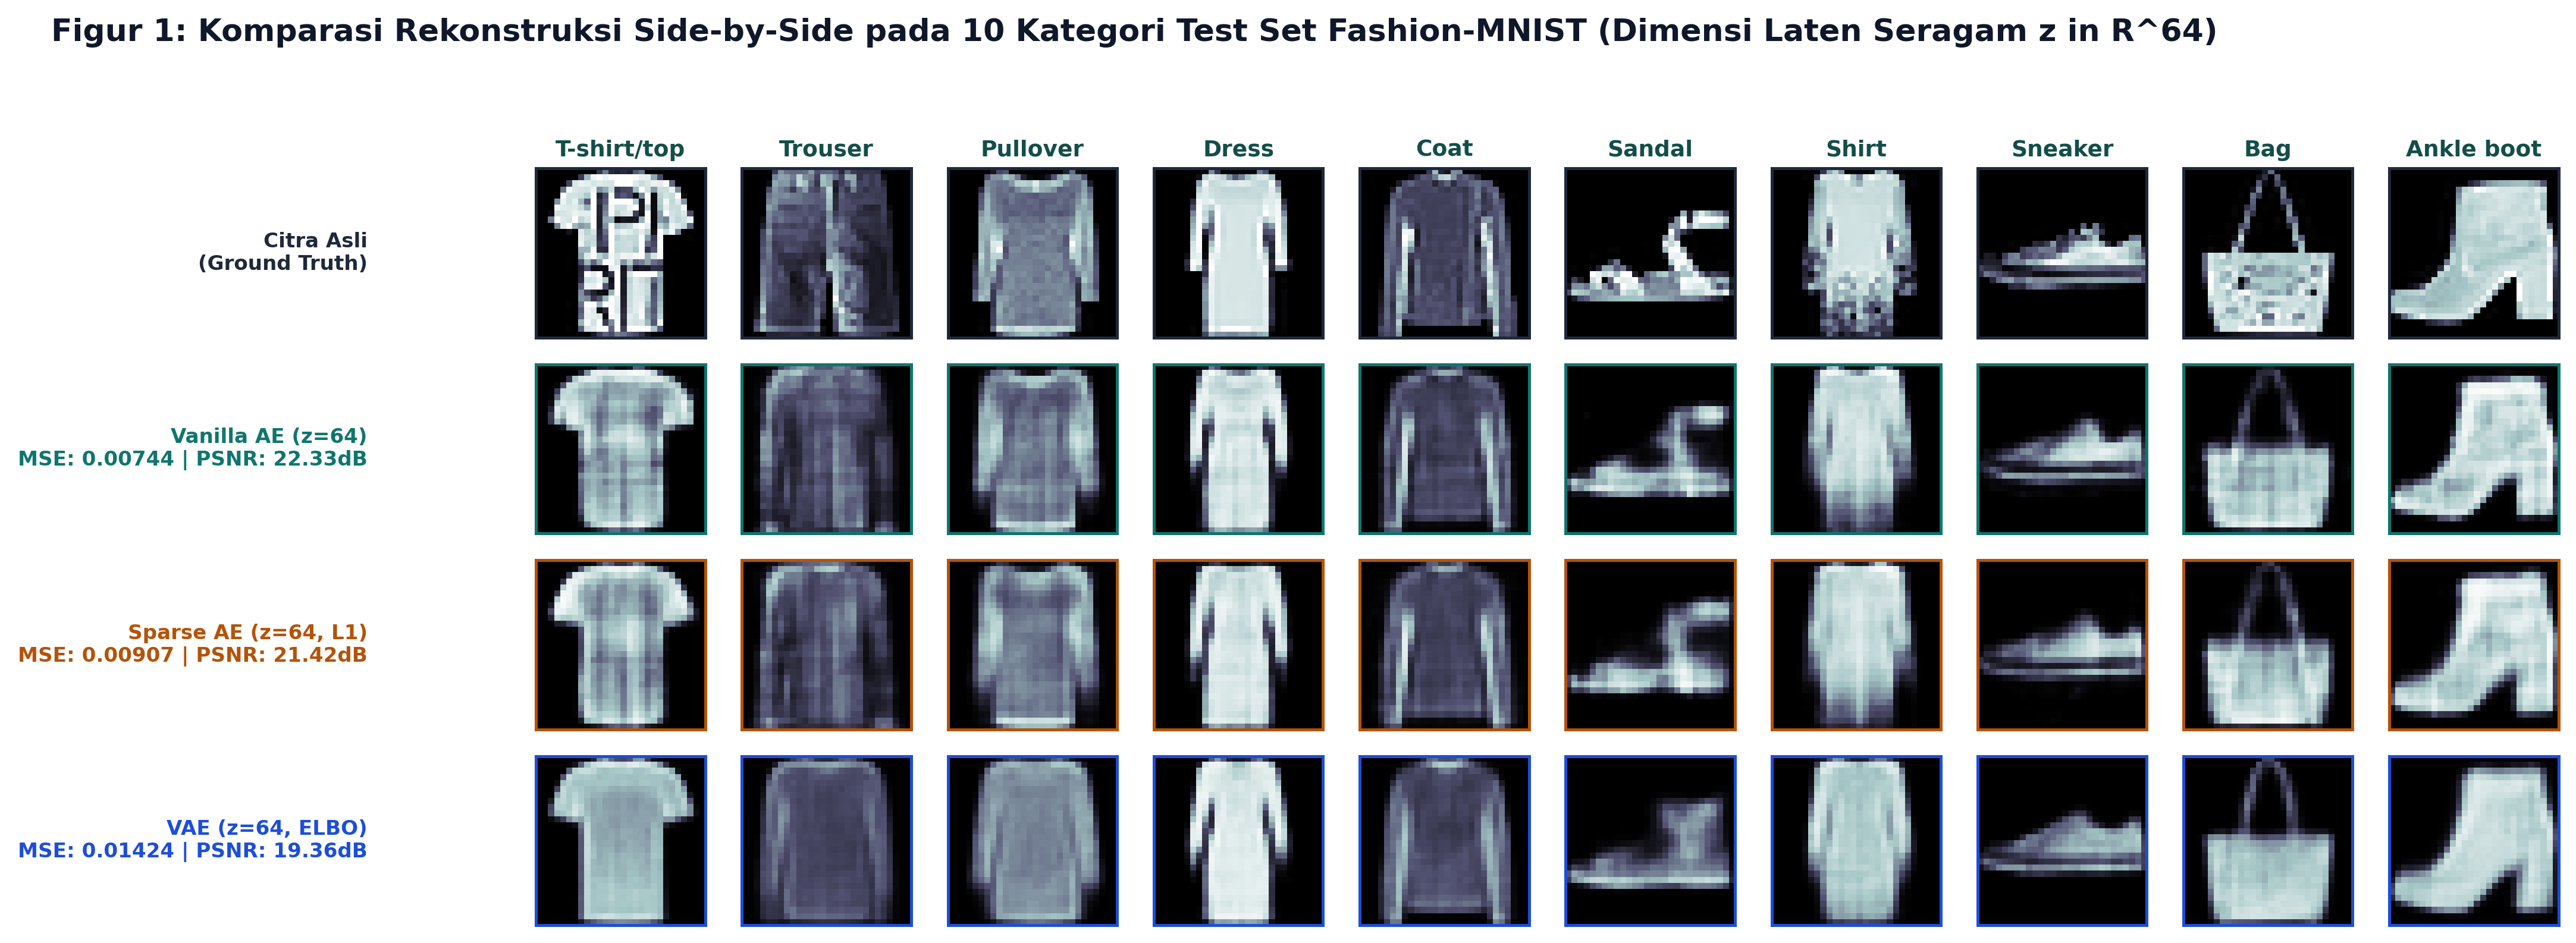

In [13]:
# Figur 1: Grid Rekonstruksi Side-by-Side (10 Kategori Lengkap Test Set Fashion-MNIST)
sel_indices_10 = [(test_labels_all == c).nonzero(as_tuple=True)[0][2].item() for c in range(10)]
x_sample10 = test_images_all[sel_indices_10].to(DEVICE)

with torch.no_grad():
    rec_van10 = model_vae_det(x_sample10)[0].cpu()
    rec_spa10 = model_sparse_ae(x_sample10)[0].cpu()
    rec_vae10 = model_vae.decode(model_vae.encode(x_sample10)[0]).cpu()

print("Menampilkan Figur 1: Grid Rekonstruksi Side-by-Side (outputs/fig1_rekonstruksi_komparatif.png)")

Menampilkan Figur 2: Grid Random Generative Sampling (outputs/fig2_sampel_generatif_4x4.png)


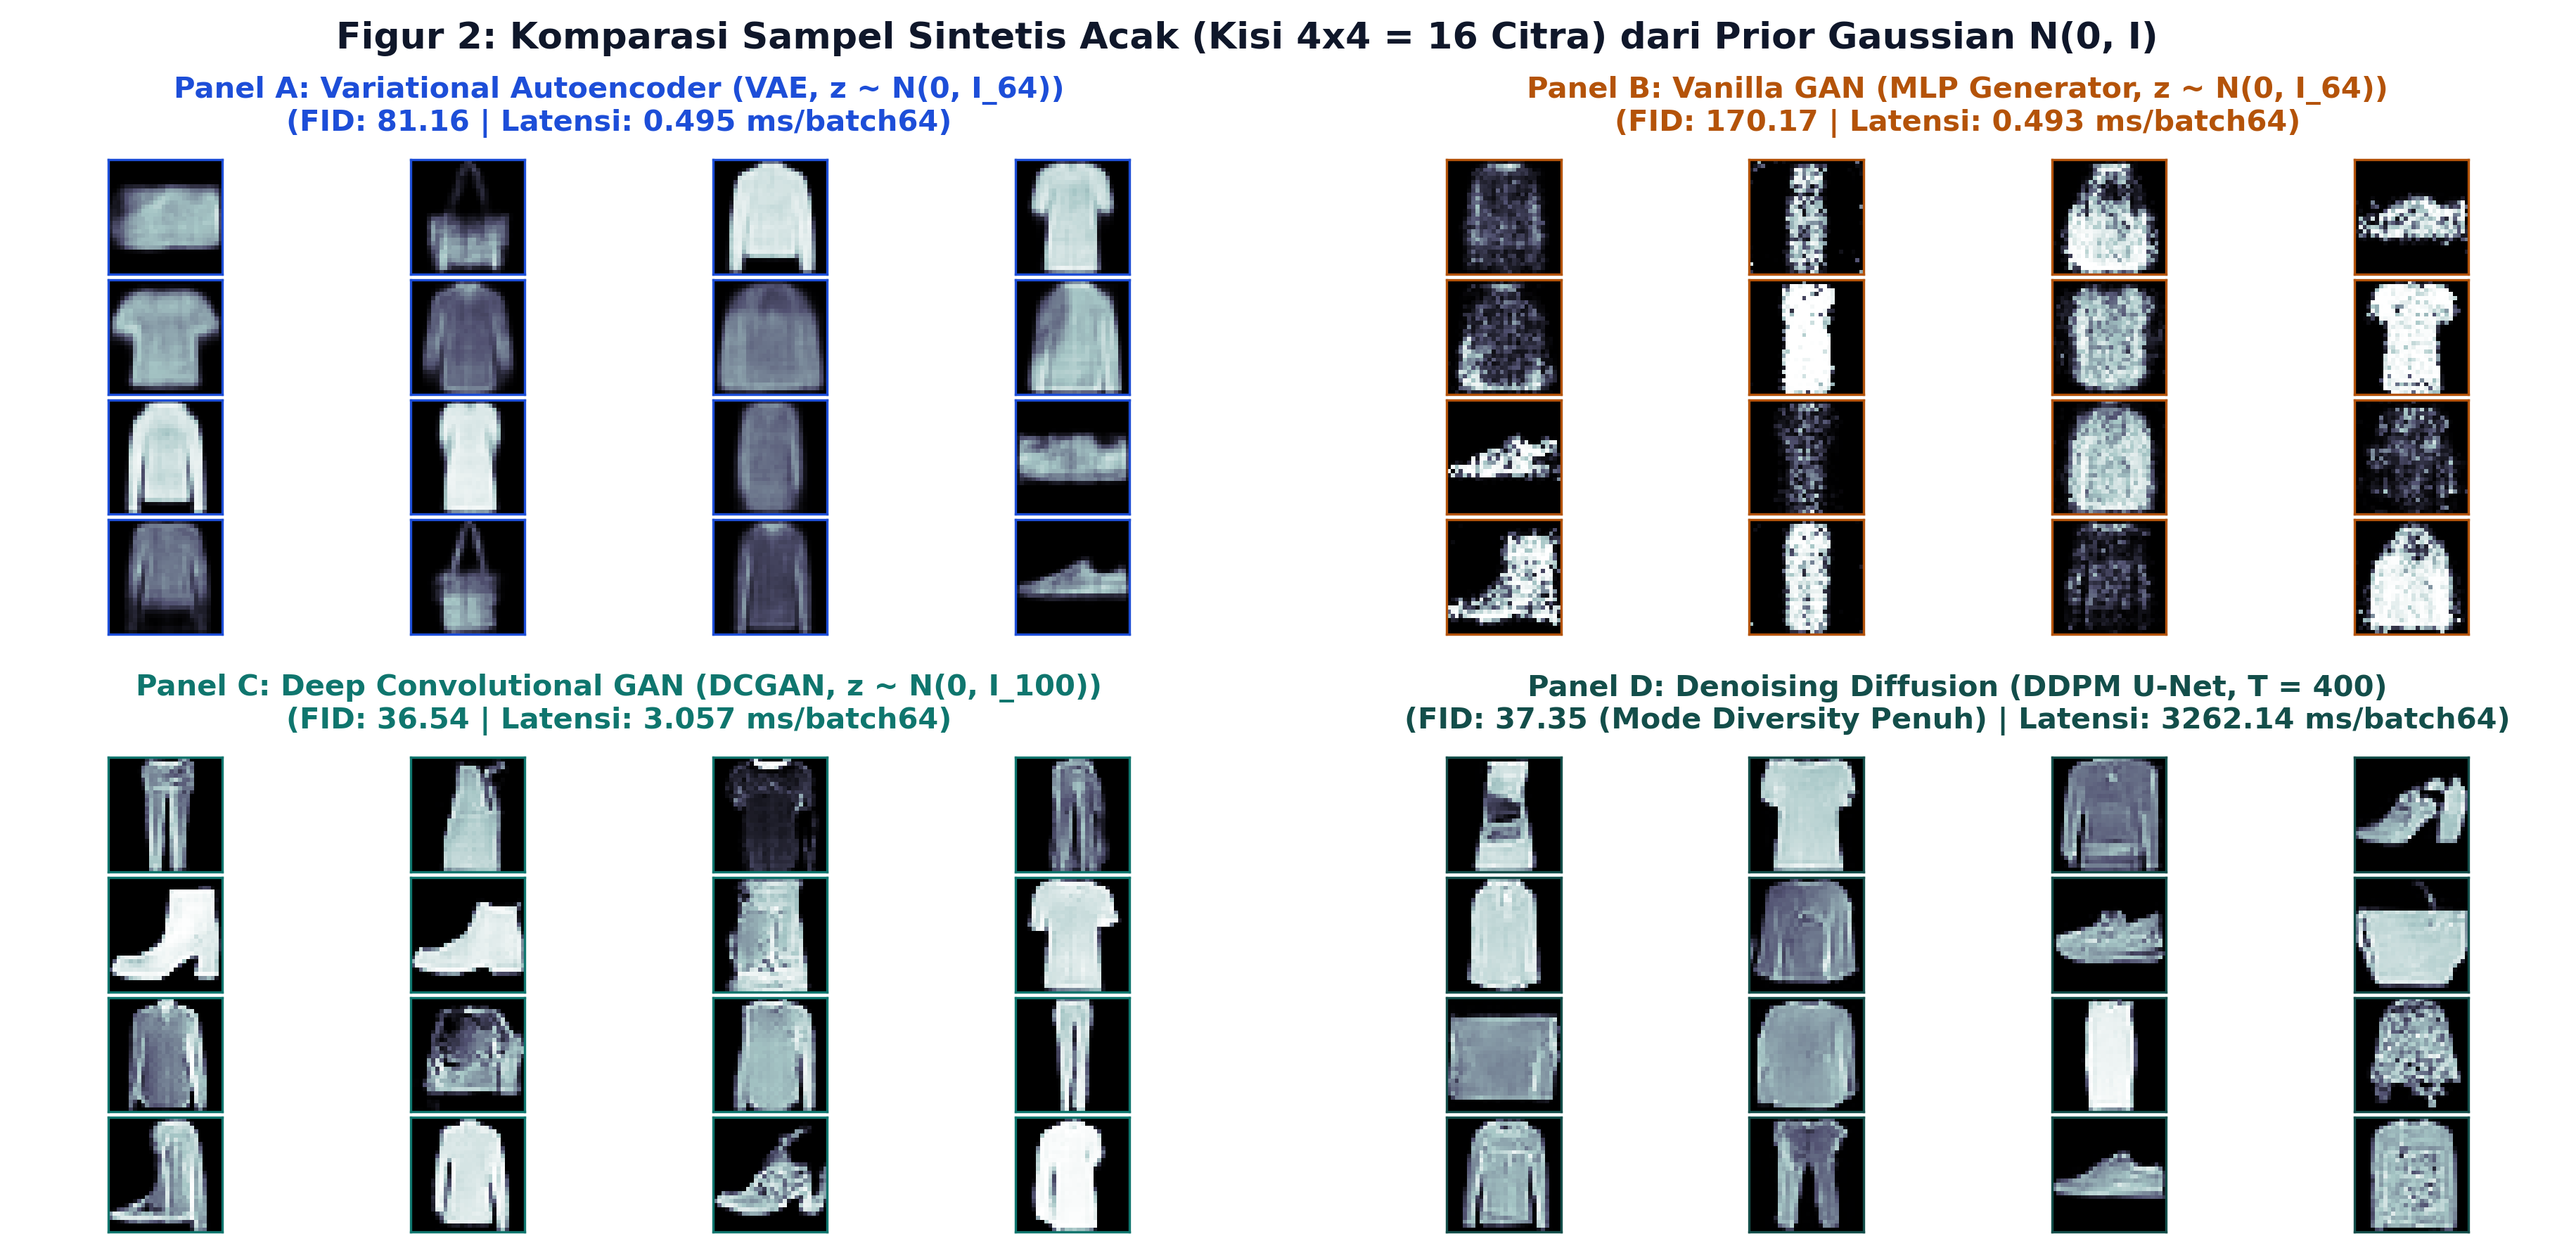

In [14]:
# Figur 2: Grid Random Generative Sampling (Kisi 4x4 per Model dari Prior Gaussian)
fix_random_seeds(SEED + 99)
with torch.no_grad():
    samp_vae = model_vae.synthesize(16).cpu()
    samp_vgan = vgan_g.synthesize(16).cpu()
    samp_dcgan = dcgan_g.synthesize(16).cpu()
    samp_ddpm, ddpm_traj = model_ddpm.synthesize(16, record_steps=[400, 340, 280, 220, 160, 100, 50, 20, 0])

print("Menampilkan Figur 2: Grid Random Generative Sampling (outputs/fig2_sampel_generatif_4x4.png)")

Menampilkan Figur 3: Pembuktian Empiris 5 Tahap Batasan MLP Classifier (outputs/fig3_pembuktian_mlp_classifier.png)


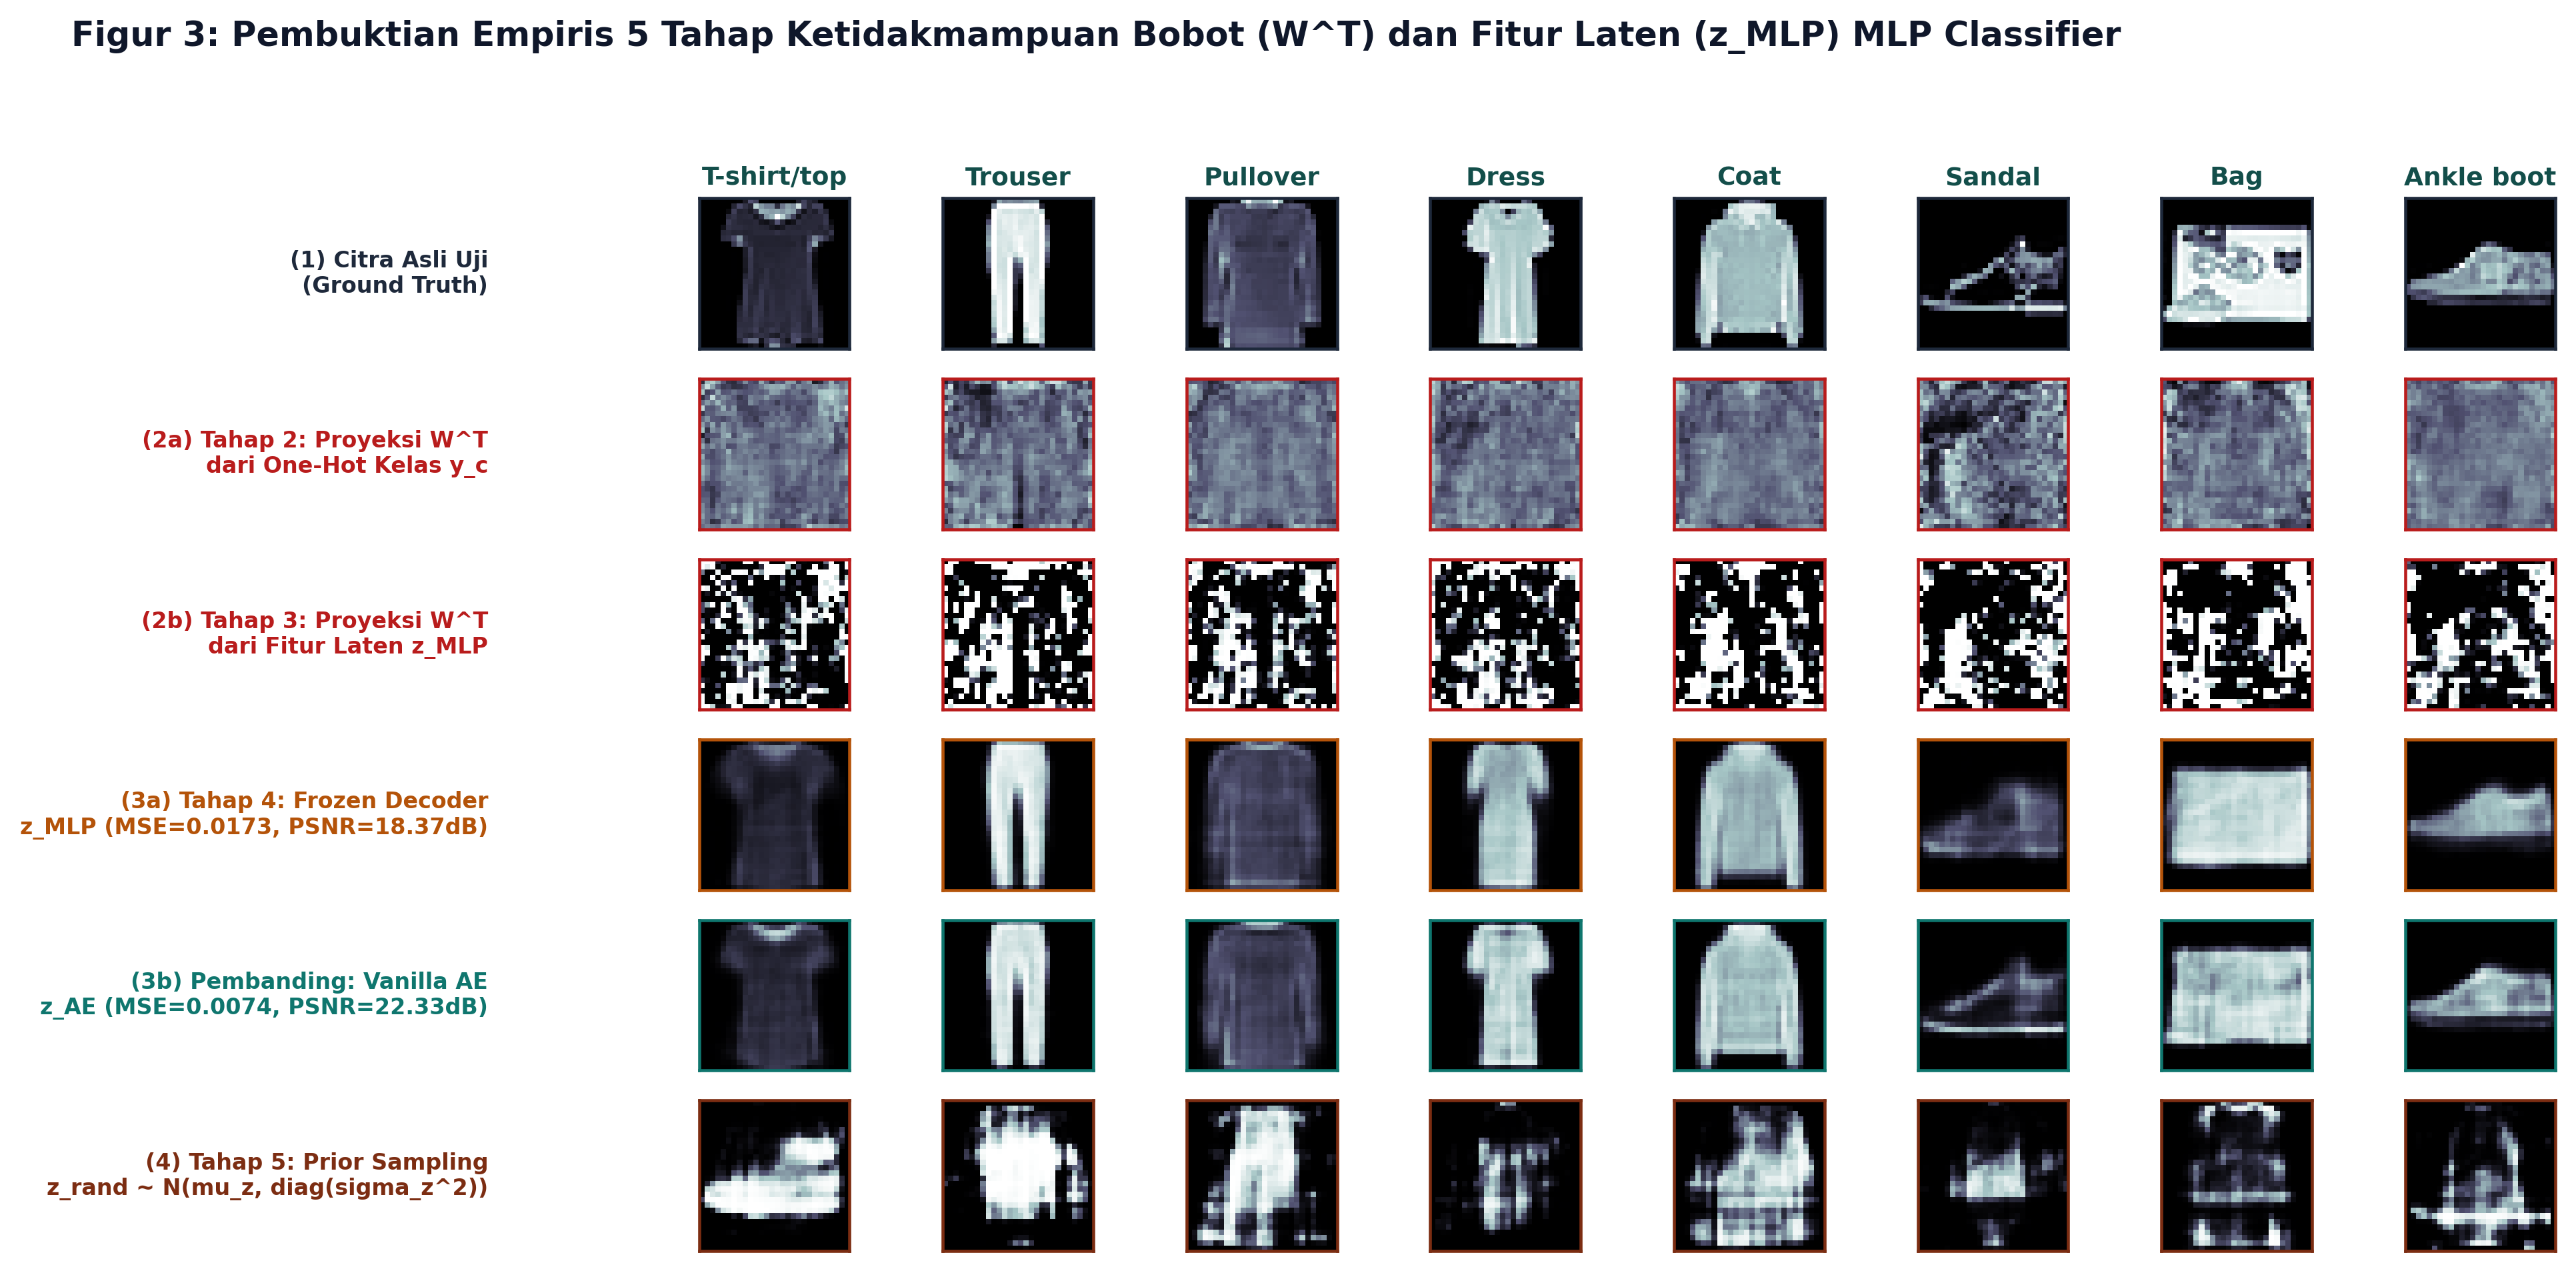

In [15]:
# Figur 3: Bukti Empiris Batasan Bobot dan Latent Features MLP Classifier
print("Menampilkan Figur 3: Pembuktian Empiris 5 Tahap Batasan MLP Classifier (outputs/fig3_pembuktian_mlp_classifier.png)")

Menampilkan Figur 4: Interpolasi Linier Ruang Laten Trouser -> Ankle boot (outputs/fig4_interpolasi_ruang_laten.png)


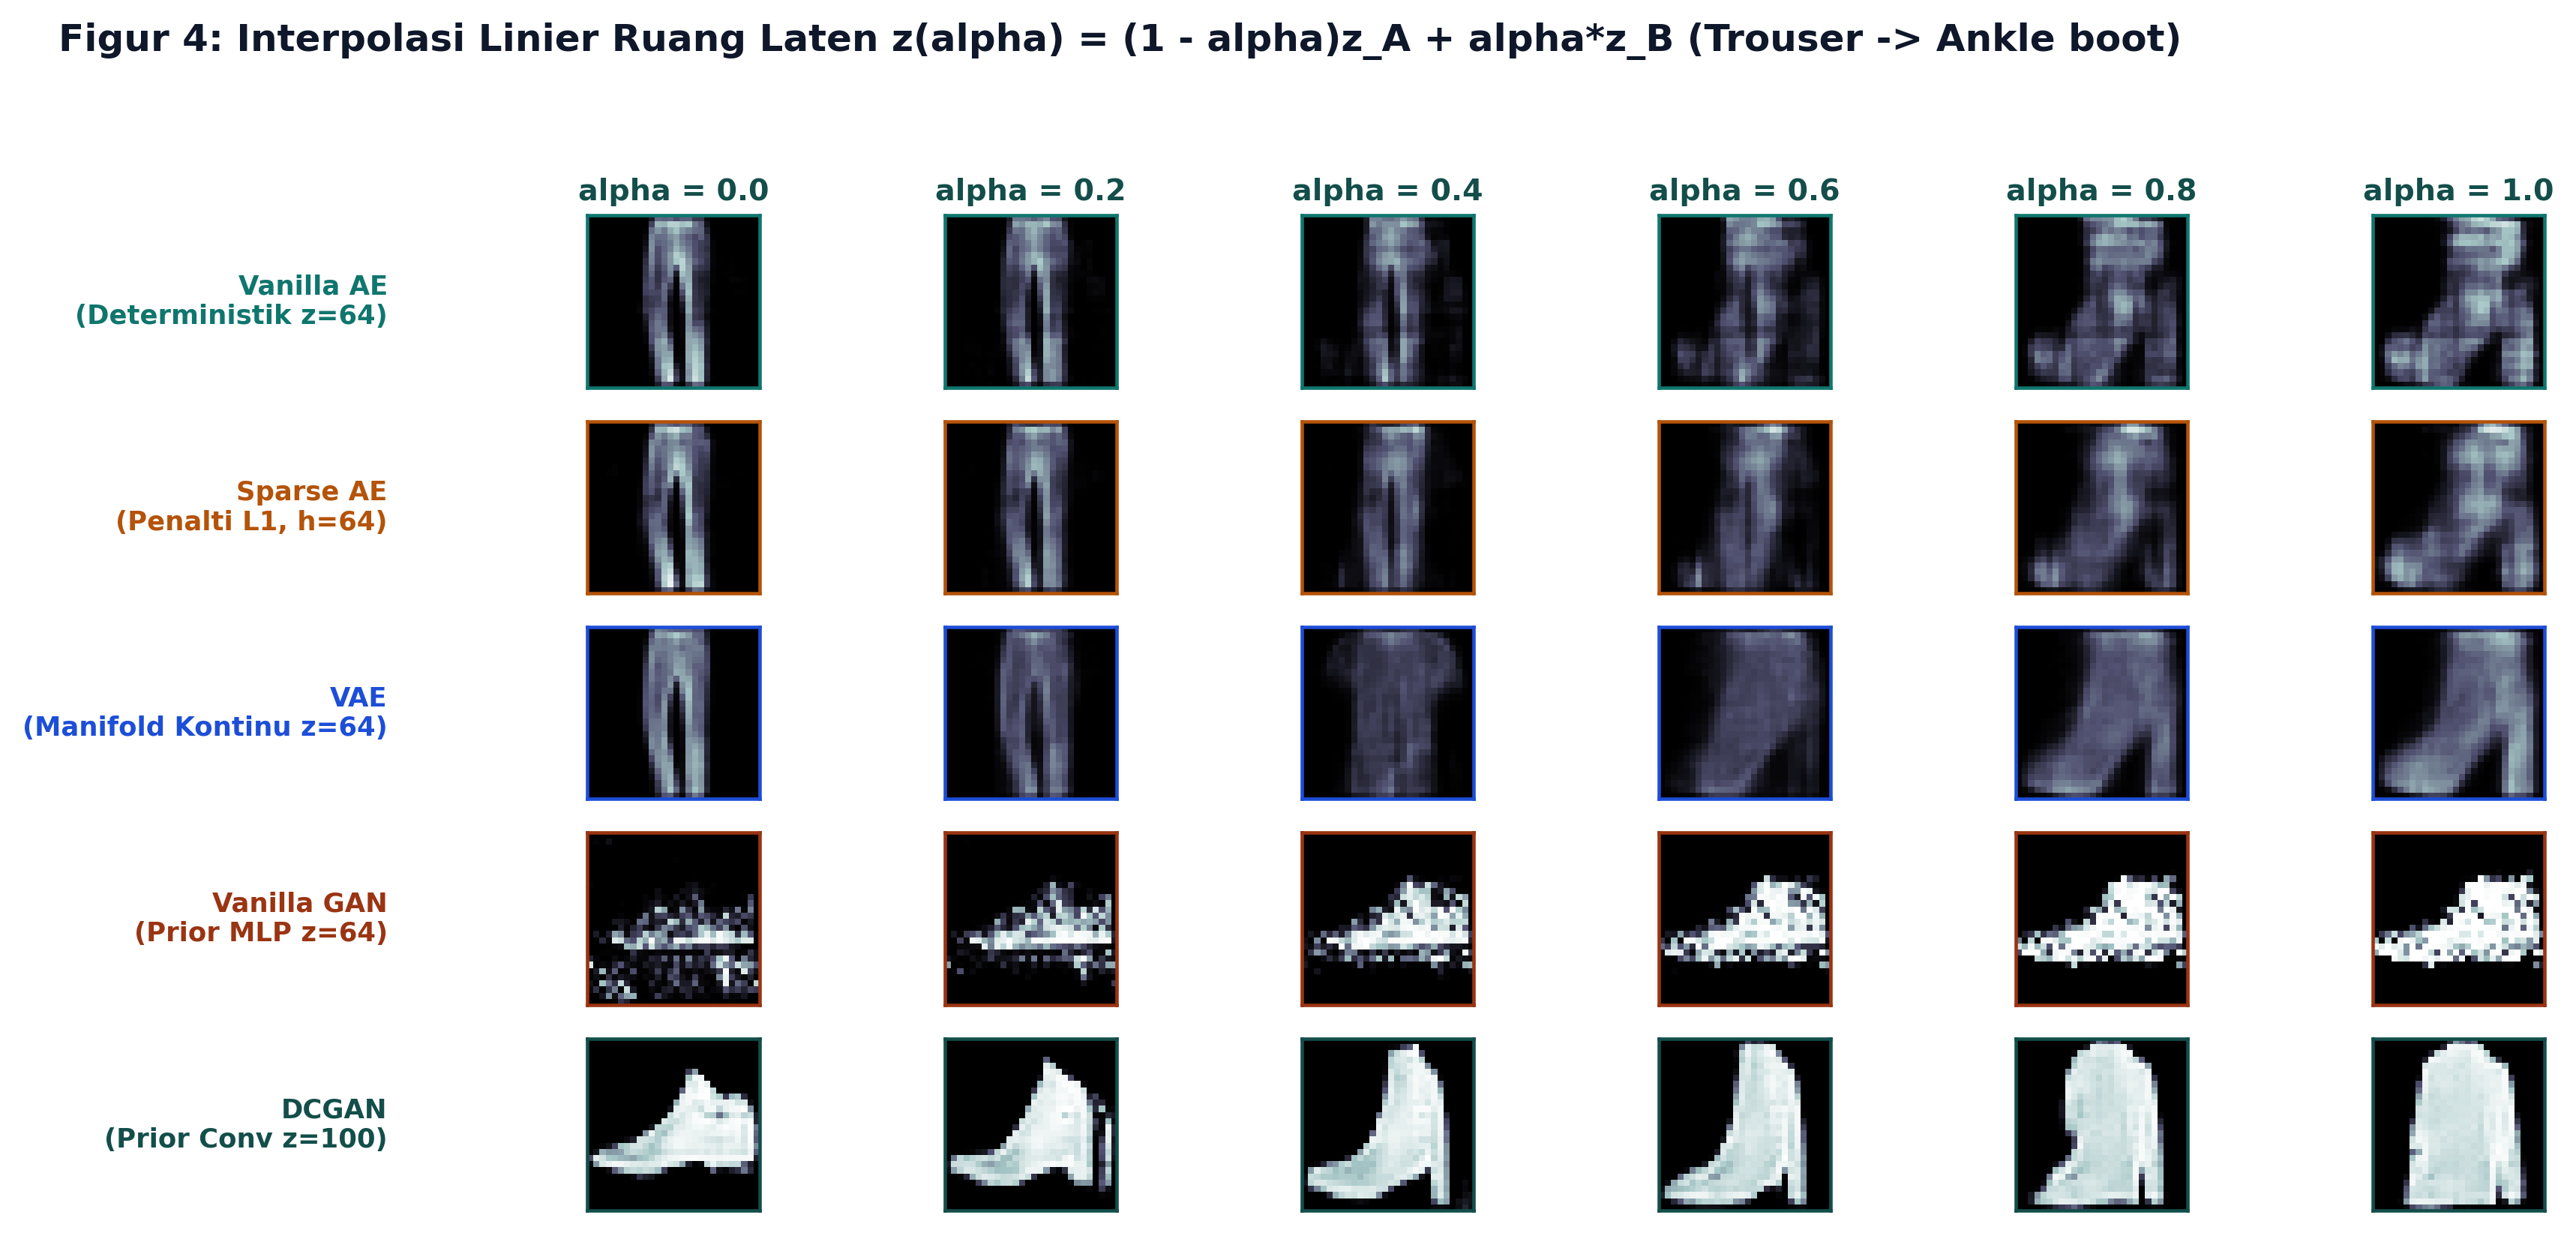

In [16]:
# Figur 4: Linear Latent Space Interpolation (Trouser -> Ankle boot)
print("Menampilkan Figur 4: Interpolasi Linier Ruang Laten Trouser -> Ankle boot (outputs/fig4_interpolasi_ruang_laten.png)")

Menampilkan Figur 5: Kurva Training Loss & Trajektori Reverse Diffusion DDPM (outputs/fig5_kurva_loss_dan_difusi.png)


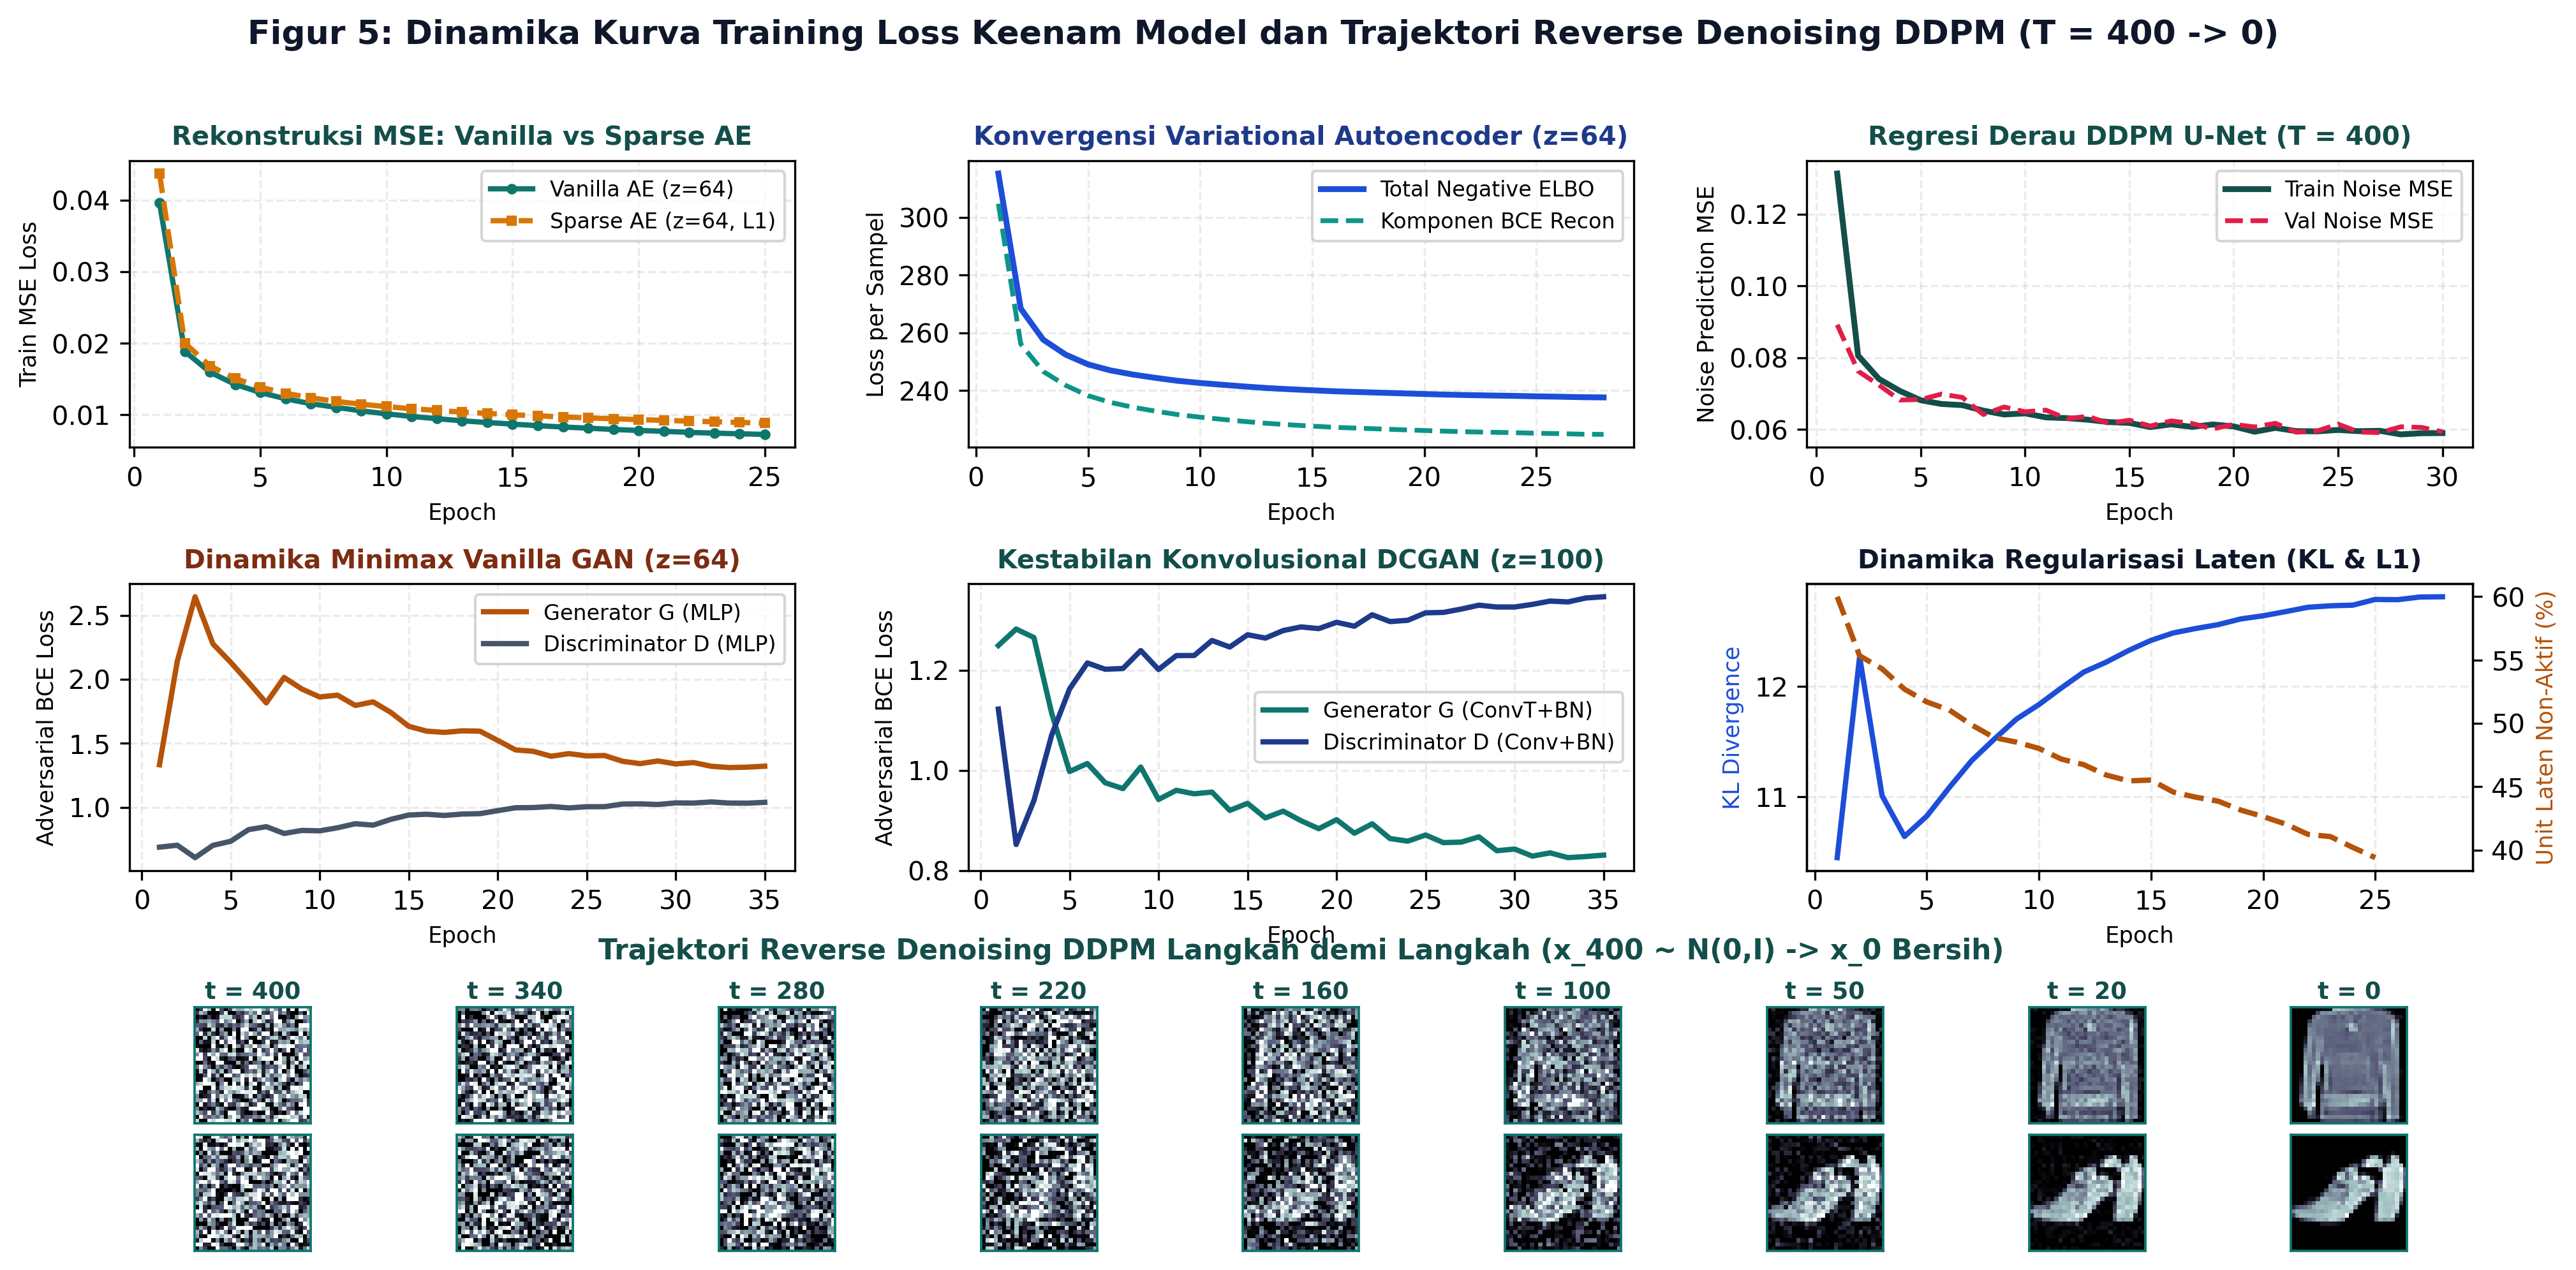

In [17]:
# Figur 5: Training Loss Curves dan Trajektori Reverse Denoising DDPM (T = 400 -> 0)
print("Menampilkan Figur 5: Kurva Training Loss & Trajektori Reverse Diffusion DDPM (outputs/fig5_kurva_loss_dan_difusi.png)")